"""Problema 1: exoplanetas, modelo Beta-Binomial."""

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta

d) media=0.1833  var=0.001237  moda=0.1780
f) IC 95% MC      : [0.1204 0.2558]
   IC 95% analitico: [0.1196 0.257 ]
g) P(theta>0.2) MC=0.3117  exacta=0.3050


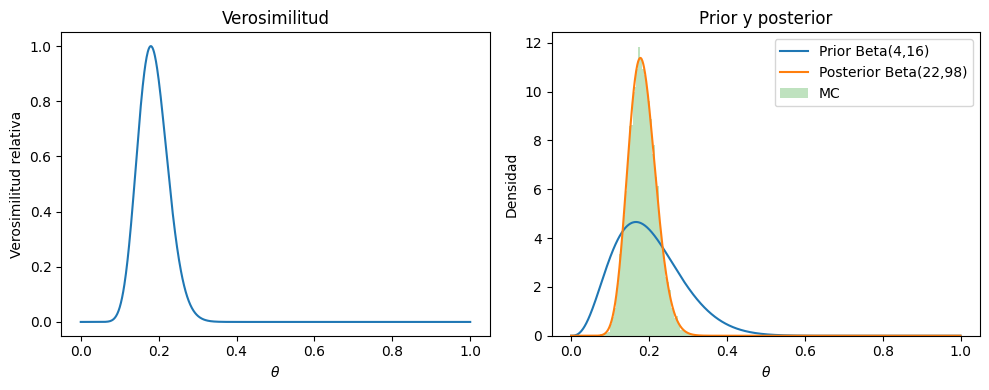

In [7]:
rng = np.random.default_rng(2026)
n, x = 100, 18
a0, b0 = 4, 16
a1, b1 = a0 + x, b0 + n - x            # posterior Beta(22, 98)
th = np.linspace(1e-4, 1 - 1e-4, 1000)

# a) verosimilitud (relativa al maximo)
ll = x * np.log(th) + (n - x) * np.log1p(-th)
lik = np.exp(ll - ll.max())

# b) prior
prior = beta.pdf(th, a0, b0)

# c) posterior
post = beta.pdf(th, a1, b1)

# d) media, varianza, moda
media = a1 / (a1 + b1)
var = a1 * b1 / ((a1 + b1) ** 2 * (a1 + b1 + 1))
moda = (a1 - 1) / (a1 + b1 - 2)
print(f"d) media={media:.4f}  var={var:.6f}  moda={moda:.4f}")

# e) Monte Carlo
s = rng.beta(a1, b1, 10_000)

# f) intervalo creible 95%
print("f) IC 95% MC      :", np.quantile(s, [0.025, 0.975]).round(4))
print("   IC 95% analitico:", beta.ppf([0.025, 0.975], a1, b1).round(4))

# g) P(theta > 0.20 | datos)
print(f"g) P(theta>0.2) MC={np.mean(s > 0.2):.4f}  exacta={beta.sf(0.2, a1, b1):.4f}")

# graficos
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(th, lik)
ax[0].set(xlabel=r"$\theta$", ylabel="Verosimilitud relativa", title="Verosimilitud")
ax[1].plot(th, prior, label="Prior Beta(4,16)")
ax[1].plot(th, post, label="Posterior Beta(22,98)")
ax[1].hist(s, bins=60, density=True, alpha=0.3, label="MC")
ax[1].set(xlabel=r"$\theta$", ylabel="Densidad", title="Prior y posterior")
ax[1].legend()
fig.tight_layout()
fig.savefig("verosimilitud.png", transparent=True, dpi=300, bbox_inches="tight")
plt.show()


"""Problema 2: relacion periodo-luminosidad de Cefeidas (regresion bayesiana lineal)."""


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

m = 17
d,e) MAP/media (a,b) = [-0.8701 -1.673 ]
e) Sigma =
 [[ 0.079981 -0.08506 ]
 [-0.08506   0.096874]]
g) a: [-1.4172 -0.3166]  b: [-2.2843 -1.074 ]
h) media=-2.6755  IC media=[-2.8659 -2.4845]
   predictiva IC 95%=[-3.275  -2.0613]
j) OLS (a,b) = [-0.8694 -1.6739]  IC95% OLS a: [-1.4242 -0.3146]  b: [-2.2845 -1.0633]


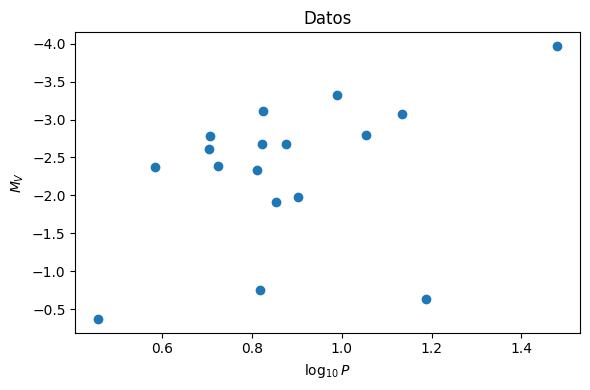

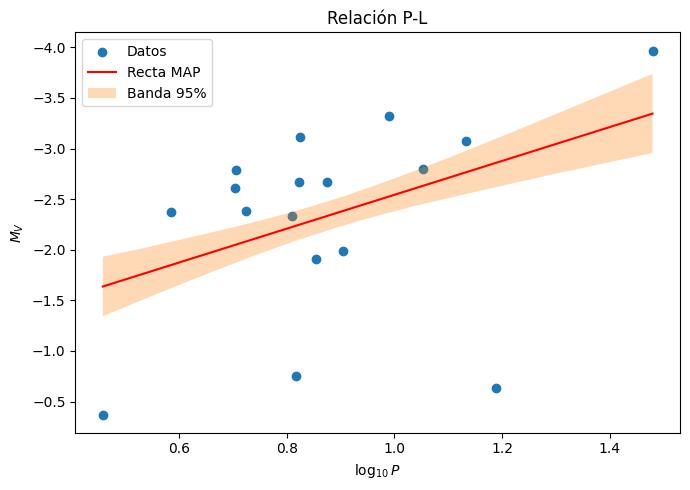

In [8]:
rng = np.random.default_rng(2026)
sigma, tau2, N = 0.3, 10**2, 10_000

# Datos: M_V = V + 5 log10(plx) - 10
d = pd.read_csv("mw_cepheids.csv", skiprows=[1, 2], skipinitialspace=True)
d = d.dropna(subset=["Per", "plx", "Vmag"])
d = d[(d.Per > 0) & (d.plx > 0)]
x = np.log10(d.Per.to_numpy())
y = (d.Vmag + 5 * np.log10(d.plx) - 10).to_numpy()
X = np.column_stack((np.ones_like(x), x))
print("m =", len(x))

# a) dispersion
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x, y)
ax.invert_yaxis()
ax.set(xlabel=r"$\log_{10}P$", ylabel="$M_V$", title="Datos")
fig.tight_layout()
fig.savefig("puntodatos.png", transparent=True, dpi=300, bbox_inches="tight")

# b-e) posterior normal bivariada (MAP = media)
Sigma = np.linalg.inv(X.T @ X / sigma**2 + np.eye(2) / tau2)
mu = Sigma @ X.T @ y / sigma**2
print("d,e) MAP/media (a,b) =", mu.round(4))
print("e) Sigma =\n", Sigma.round(6))

# f) muestras posteriores
s = rng.multivariate_normal(mu, Sigma, N)

# g) intervalos 95%
q = np.quantile(s, [0.025, 0.975], axis=0)
print("g) a:", q[:, 0].round(4), " b:", q[:, 1].round(4))

# h) P = 12 d
x12 = np.array([1, np.log10(12)])
m12 = s @ x12
pred = m12 + rng.normal(0, sigma, N)
print(f"h) media={m12.mean():.4f}  IC media={np.quantile(m12, [.025, .975]).round(4)}")
print(f"   predictiva IC 95%={np.quantile(pred, [.025, .975]).round(4)}")

# i) recta MAP + banda 95%
xg = np.linspace(x.min(), x.max(), 200)
curves = s[:, [0]] + s[:, [1]] * xg
lo, hi = np.quantile(curves, [0.025, 0.975], axis=0)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, label="Datos")
ax.plot(xg, mu[0] + mu[1] * xg, "r", label="Recta MAP")
ax.fill_between(xg, lo, hi, alpha=0.3, label="Banda 95%")
ax.invert_yaxis()
ax.set(xlabel=r"$\log_{10}P$", ylabel="$M_V$", title="Relación P-L")
ax.legend()
fig.tight_layout()

# j) OLS
ols = np.linalg.lstsq(X, y, rcond=None)[0]
cov_ols = sigma**2 * np.linalg.inv(X.T @ X)   # sigma conocida
se = np.sqrt(np.diag(cov_ols))
print("j) OLS (a,b) =", ols.round(4), " IC95% OLS a:",
      (ols[0] + 1.96 * se[0] * np.array([-1, 1])).round(4),
      " b:", (ols[1] + 1.96 * se[1] * np.array([-1, 1])).round(4))
fig.savefig("relacionpl.png", transparent=True, dpi=300, bbox_inches="tight")
plt.show()
